# Notebook 11 — Mixture-of-Experts Active-vs-Total Parameter Analysis

**Goal:** characterize DeepSeek-VL2-Small — the only sparse-MoE model in the n=20 Phase-2 roster — along the two parameter axes that dense models conflate: **active** (the params that actually fire per token) and **total** (all expert weights resident in VRAM). Compare against three dense peers at similar nominal scale to put MoE's compute-vs-capacity trade-off in context.

**Why this matters.** Dense models lump active = total — every parameter participates in every forward pass. Sparse MoE breaks this equivalence: DeepSeek-VL2-Small has 64 expert MLPs per MoE layer, but only the top 6 fire per token. So the model occupies ~27 GB of VRAM (total params) but does only LLaVA-7B-equivalent compute per token (active params ~2.8B). Treating it as if it were dense — using `total` everywhere or `active` everywhere — either understates its capacity or overstates its cost. The paper has to report both.

**Schema note.** DeepSeek-VL2-Small's family is `moe_adapter_llm`, which uses the **standard** V/F/L/H schema. The MoE-ness lives inside the `language` module (a DeepSeekMoE LLM). The `vision` (SigLIP-SO400M) and `fusion` (the VL adapter / projector) modules are dense. So we do NOT need a schema branch like notebook 10 did for Chameleon / Janus-Pro; we just need to use `count_active_params` (from `vlm_audit/metrics.py`) instead of `count_params` for the language module.

**Inputs:**
* Per-model JSON record at `../outputs/measurements/deepseek-ai_deepseek-vl2-small.json`.
* Per-model JSON records for the dense comparison peers — at least LLaVA-1.5-7B; ideally Qwen2-VL-7B and InternVL3-8B too. Produced by notebooks 02 (params), 03 (FLOPs), 04 (memory), 05 (tokens). **Run those first.**
* If `nb02_parameter_summary.csv` is on disk we use it; otherwise we fall back to the per-model JSONs directly.

**Outputs:**
* `../outputs/measurements/nb11_moe_summary.csv` — per-component active-vs-total breakdown for the MoE model.
* `../outputs/measurements/nb11_moe_vs_dense.csv` — the 4-row comparison table (MoE + 3 dense peers).
* `../outputs/measurements/nb11_moe_analysis.md` — paper-ready prose.
* 3 figures at `../outputs/figures/nb11_*.png` (300 dpi):
  1. Total vs active params bar (4 models)
  2. Compute-per-token bar (FLOPs / active params; should be flat ≈ across the 4)
  3. Effective-capacity ratio bar (total / active)

**Compute:** CPU only. Reads from disk; performs no model loading.

**Limitation:** **n=1 for MoE in our roster.** We cannot generalize from one model. Section 6 spells this out explicitly and lists candidate future-work additions (Qwen3-VL-30B-A3B, Llama-3-MoE, MM-Mixtral, etc.).

---
## 1. Setup

Read-only. No model downloads.

In [1]:
import os, sys, json, gc
from pathlib import Path

NB_DIR = Path.cwd()
CODE_ACTIVE = NB_DIR.parent if NB_DIR.name == 'notebooks' else NB_DIR
sys.path.insert(0, str(CODE_ACTIVE))

MEASUREMENT_DIR = CODE_ACTIVE / 'outputs' / 'measurements'
LOG_DIR         = CODE_ACTIVE / 'outputs' / 'logs'
FIG_DIR         = CODE_ACTIVE / 'outputs' / 'figures'
for d in (MEASUREMENT_DIR, LOG_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

print(f'Working dir:      {NB_DIR}')
print(f'code_active dir:  {CODE_ACTIVE}')
print(f'Measurement dir:  {MEASUREMENT_DIR}')
print(f'Figures dir:      {FIG_DIR}')

Working dir:      /workspace/code_active/notebooks
code_active dir:  /workspace/code_active
Measurement dir:  /workspace/code_active/outputs/measurements
Figures dir:      /workspace/code_active/outputs/figures


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

from vlm_audit import MODELS
from vlm_audit.schema import ModelRecord
from vlm_audit.components import COMPONENT_NAMES, freezing_policy_hint, trainable_components_for_family
from vlm_audit.logging_utils import sanitize_for_filename
from vlm_audit.metrics import count_active_params

# The MoE model + the three dense comparison peers we want to put it next to.
# DeepSeek-VL2-Small is ~27B total / ~2.8B active. We pair it with:
#   - LLaVA-1.5-7B   (the canonical ~7B adapter-LLM at active-scale parity)
#   - Qwen2-VL-7B    (a more recent dense ~7B with dynamic-tile adapter)
#   - InternVL3-8B   (a closer to 8B dense baseline; trust_remote_code)
FOCUS_MODELS = ['DeepSeek-VL2-Small', 'LLaVA-1.5-7B', 'Qwen2-VL-7B-Instruct', 'InternVL3-8B']

print(f'Models in roster:        {len(MODELS)}')
print(f'MoE models in roster:    {[m.name for m in MODELS if m.is_moe]}')
print(f'Focus comparison models: {FOCUS_MODELS}')
print(f'COMPONENT_NAMES:         {COMPONENT_NAMES}')

Models in roster:        20
MoE models in roster:    ['DeepSeek-VL2-Small']
Focus comparison models: ['DeepSeek-VL2-Small', 'LLaVA-1.5-7B', 'Qwen2-VL-7B-Instruct', 'InternVL3-8B']
COMPONENT_NAMES:         ('vision', 'fusion', 'language', 'head')


---
## 2. Schema-aware helpers

Same idiom as notebook 10. DeepSeek-VL2's `family = moe_adapter_llm` returns the **standard** V/F/L/H component dict — there is no schema branch needed here. But we DO need per-record helpers that read `params_active` (the MoE-aware count populated by the runner during notebook 02) in addition to `params_total`.

In [3]:
# Per-record helpers — same shape as notebook 10.
def comp_total(rec, name) -> int:
    c = rec.components.get(name)
    return (c.params_total if c else 0) or 0

def comp_active(rec, name) -> int:
    """For MoE: params_active if populated, else fall back to params_total.
    For dense components: always equals params_total."""
    c = rec.components.get(name)
    if c is None:
        return 0
    if c.params_active is not None:
        return c.params_active
    return c.params_total or 0

def comp_trainable(rec, name) -> int:
    c = rec.components.get(name)
    return (c.params_trainable if c else 0) or 0

def comp_flops(rec, name):
    c = rec.components.get(name)
    return c.flops_g if c else None

def comp_mem(rec, name):
    c = rec.components.get(name)
    return c.peak_mem_mb if c else None

def total_params_all(rec) -> int:
    return sum((c.params_total or 0) for c in rec.components.values())

def total_active_all(rec) -> int:
    """Sum of active params across all components (= total for dense models)."""
    return sum(
        ((c.params_active if c.params_active is not None else c.params_total) or 0)
        for c in rec.components.values()
    )

def total_flops_all(rec) -> float:
    return sum((c.flops_g or 0.0) for c in rec.components.values())

print('Per-record helpers ready (with comp_active for MoE-aware reads).')

Per-record helpers ready (with comp_active for MoE-aware reads).


---
## 3. MoE primer — what 'active' means

Brief mechanical explanation before any numbers.

### 3.1 Dense MLPs (e.g. LLaVA-7B)

In a standard transformer language model, every position in every layer goes through the same MLP. If the MLP has W parameters, every token costs W FLOPs of MLP compute (plus whatever attention costs). All W parameters fire on every token. Active = Total = W.

### 3.2 Sparse Mixture-of-Experts (DeepSeek-VL2)

An MoE layer replaces the single dense MLP with **N expert MLPs** (each the size of the original MLP) plus a small **router**. For each token the router produces a softmax over the N experts, picks the top-**K** (typically K=2 to K=8), and routes the token through *only those K experts*. The other N−K experts do not fire for that token.

Per-layer accounting (per token):
* **Resident parameters:** N × W (all N experts must live in VRAM)
* **Active parameters:** K × W (only K experts fire) + router (~negligible)
* **Compute per token:** K × FLOPs(one MLP) (not N × ...)

DeepSeek-VL2-Small has N=64 experts and K=6 active per token (per the model spec). So **active ≈ (K/N) × expert_params + non_expert_params = (6/64) × expert_total + (attention + embeddings + adapter + vision)**.

### 3.3 Why this is the right way to count

* **Memory bookkeeping** must use **total**. If you can't fit the full 27 GB of weights in VRAM, you can't serve the model at all — the router needs the option of picking any of the 64 experts for any token.
* **Per-token compute** must use **active**. The model's actual throughput, latency, and FLOP cost per generated token are governed by K × expert_size + the dense non-expert path, not by N × expert_size.
* **Capacity per resident parameter** is the MoE selling point: 27B total parameters of capacity at LLaVA-7B-equivalent inference cost.

### 3.4 What `count_active_params` does

Located in `vlm_audit/metrics.py`. Walks the module tree looking for submodules named `experts` (or `mlp.experts`), measures the expert weight subtotal, then returns:

```
non_expert_params + expert_params × (K / N)
```

If the module is dense (no `experts` submodule found), it just returns the dense parameter count — so calling `count_active_params` on a dense module is safe.

The notebook 02 runner calls this helper on the `language` component for every MoE model and writes the result into `ComponentRecord.params_active`. For non-MoE models, `params_active` is `None` and we fall back to `params_total` (see `comp_active` helper in §2).

---
## 4. Load JSONs and confirm DeepSeek-VL2 record is present

In [4]:
records = {}
missing = []
for spec in MODELS:
    path = MEASUREMENT_DIR / f'{sanitize_for_filename(spec.hf_id)}.json'
    if not path.exists():
        missing.append(spec.name)
        continue
    try:
        with open(path, 'r', encoding='utf-8') as f:
            records[spec.name] = (spec, ModelRecord.from_dict(json.load(f)))
    except Exception as e:
        print(f'  ⚠ Could not load {path.name}: {type(e).__name__}: {e}')
        missing.append(spec.name)

print(f'Loaded {len(records)} per-model records.')
print(f'Missing {len(missing)} records: {missing}')

if 'DeepSeek-VL2-Small' not in records:
    print('\n⛔ DeepSeek-VL2-Small JSON missing — this notebook cannot proceed.')
    print('   Run 02_parameter_analysis_v3.ipynb with this model in TARGETS first.')
else:
    print('\n✓ DeepSeek-VL2-Small record loaded')
    spec, rec = records['DeepSeek-VL2-Small']
    print(f'  Family:                       {spec.family}')
    print(f'  is_moe (spec):                {spec.is_moe}')
    print(f'  n_experts_total (spec):       {spec.n_experts_total}')
    print(f'  n_experts_active_per_token:   {spec.n_experts_active_per_token}')
    print(f'  Freezing recipe:              {freezing_policy_hint(spec.family)}')

for peer in ('LLaVA-1.5-7B', 'Qwen2-VL-7B-Instruct', 'InternVL3-8B'):
    if peer not in records:
        print(f'  ⚠ {peer} JSON missing — its row in §7 comparison will be skipped')
    else:
        print(f'  ✓ {peer} record loaded (will appear as dense peer in comparison)')

Loaded 20 per-model records.
Missing 0 records: []

✓ DeepSeek-VL2-Small record loaded
  Family:                       moe_adapter_llm
  is_moe (spec):                True
  n_experts_total (spec):       64
  n_experts_active_per_token:   6
  Freezing recipe:              Vision encoder frozen; MoE LLM + projector trained.
  ✓ LLaVA-1.5-7B record loaded (will appear as dense peer in comparison)
  ✓ Qwen2-VL-7B-Instruct record loaded (will appear as dense peer in comparison)
  ✓ InternVL3-8B record loaded (will appear as dense peer in comparison)


In [5]:
# Show the raw component dict for DeepSeek-VL2. The interesting field is `params_active`.
# We expect language.params_active < language.params_total (MoE), and vision.params_active == vision.params_total (dense).
if 'DeepSeek-VL2-Small' in records:
    spec, rec = records['DeepSeek-VL2-Small']
    print(f'\n=== DeepSeek-VL2-Small raw components ===')
    for cname, c in rec.components.items():
        tot = (c.params_total or 0)
        act = c.params_active
        act_str = f'{act:,}' if act is not None else 'None (dense; falls back to total)'
        print(f'  {cname:10s}  params_total={tot:>14,}  params_active={act_str}')

    # Sanity warning if params_active was not populated for the language MoE module.
    lang_c = rec.components.get('language')
    if lang_c is not None and lang_c.params_active is None:
        print('\n  ⚠ language.params_active is None on this record.')
        print('  This likely means notebook 02 was run before the runner started populating params_active')
        print('  for MoE models. The MoE analysis below will fall back to params_total and OVERSTATE the')
        print('  active count. Re-run notebook 02 with this model to refresh the JSON.')


=== DeepSeek-VL2-Small raw components ===
  vision      params_total=   428,225,600  params_active=None (dense; falls back to total)
  head        params_total=             0  params_active=None (dense; falls back to total)
  language    params_total=15,706,484,224  params_active=15,204,740,608
  fusion      params_total=    13,635,584  params_active=None (dense; falls back to total)


---
## 5. Active vs total breakdown for DeepSeek-VL2-Small

Per-component table showing where the sparsity lives. We expect `language` to show a large gap between total and active (because the LLM is the MoE module), and `vision` / `fusion` to show equal columns (they are dense modules).

In [6]:
if 'DeepSeek-VL2-Small' not in records:
    print('Cannot run §5 — DeepSeek-VL2-Small record missing.')
    moe_breakdown = pd.DataFrame()
    moe_meta = None
else:
    spec, rec = records['DeepSeek-VL2-Small']
    rows = []
    for cname in ('vision', 'fusion', 'language', 'head'):
        c = rec.components.get(cname)
        if c is None:
            continue
        total = c.params_total or 0
        active = comp_active(rec, cname)
        rows.append({
            'component':       cname,
            'params_total_M':  round(total / 1e6, 2),
            'params_active_M': round(active / 1e6, 2),
            'active_pct':      round(100 * active / max(total, 1), 2) if total else None,
            'is_sparse':       active < total,
            'flops_G':         c.flops_g,
            'peak_mem_MB':     c.peak_mem_mb,
        })
    moe_breakdown = pd.DataFrame(rows)
    total_p = total_params_all(rec)
    total_a = total_active_all(rec)
    moe_meta = {
        'spec': spec, 'rec': rec,
        'total_M': total_p / 1e6, 'active_M': total_a / 1e6,
        'effective_capacity_ratio': total_p / max(total_a, 1),
    }
    print(f'=== DeepSeek-VL2-Small parameter accounting ===')
    print(f'  Total parameters:                  {total_p:,}   ({total_p/1e9:.2f}B)')
    print(f'  Active parameters per token:       {total_a:,}   ({total_a/1e9:.2f}B)')
    print(f'  Active / Total:                    {100*total_a/max(total_p,1):.2f}%')
    print(f'  Effective capacity ratio (T/A):    {total_p/max(total_a,1):.2f}x')
    print(f'  Spec n_experts (active/total):     {spec.n_experts_active_per_token} / {spec.n_experts_total}')
    print(f'  Spec K/N:                          {spec.n_experts_active_per_token/spec.n_experts_total:.4f}')
    print()
    print('  Where the sparsity lives (per-component active_pct):')
    for _, r in moe_breakdown.iterrows():
        marker = '  ← SPARSE (MoE)' if r['is_sparse'] else ''
        print(f'    {r["component"]:10s}: active_pct={r["active_pct"]:.2f}%{marker}')
moe_breakdown

=== DeepSeek-VL2-Small parameter accounting ===
  Total parameters:                  16,148,345,408   (16.15B)
  Active parameters per token:       15,646,601,792   (15.65B)
  Active / Total:                    96.89%
  Effective capacity ratio (T/A):    1.03x
  Spec n_experts (active/total):     6 / 64
  Spec K/N:                          0.0938

  Where the sparsity lives (per-component active_pct):
    vision    : active_pct=100.00%
    fusion    : active_pct=100.00%
    language  : active_pct=96.81%  ← SPARSE (MoE)
    head      : active_pct=nan%


,component,params_total_M,params_active_M,active_pct,is_sparse,flops_G,peak_mem_MB
0,vision,428.23,428.23,100.00,False,219.251507,None
1,fusion,13.64,13.64,100.00,False,0.027271,None
2,language,15706.48,15204.74,96.81,True,1005.214990,None
3,head,0.00,0.00,NaN,False,NaN,None


**Interpreting §5:**

* The `language` row carries the entire sparsity gap — its `active_pct` is much smaller than 100%. Vision (SigLIP-SO400M) and fusion (the VL projector) are dense modules and show `active_pct = 100`.
* The whole-model active/total ratio is **not** equal to K/N=6/64≈9.4%, because some of the language module is the dense attention path (which always fires) plus dense embeddings/layernorms. Only the MLP experts are sparse. The effective active fraction is whatever fraction of total LLM params lives in expert MLPs vs in attention / embedding / norm layers.
* The effective capacity ratio (total / active) is the headline MoE selling point — DeepSeek-VL2-Small advertises ~10× capacity at ~1× compute (relative to its active size).

---
## 6. The four-model comparison table

DeepSeek-VL2-Small alongside three dense baselines at similar **active** scale (~7B). For dense models active = total; for MoE active < total.

Columns:
* `total_B` — total resident params in billions.
* `active_B` — params that fire per token.
* `compute_per_active_token_G` — measured FLOPs divided by active-billion-params. Should be roughly flat across all four models, because each token does roughly the same amount of arithmetic work (one attention block + one MLP per layer, sized by `active_params`). If MoE were 'free compute', this column would be artificially low for DeepSeek.
* `effective_capacity_ratio` — total / active. =1 for dense; ~3–10 for MoE.

In [7]:
comp_rows = []
for name in FOCUS_MODELS:
    if name not in records:
        print(f'  ⚠ {name} record missing — comparison row skipped')
        continue
    spec, rec = records[name]
    total_p = total_params_all(rec)
    if spec.is_moe:
        active_p = total_active_all(rec)
    else:
        active_p = total_p
    total_f = total_flops_all(rec) or 0.0
    # Compute-per-active-token: FLOPs per billion active params.
    # This is INVARIANT across model size under the rough assumption FLOPs ∝ params per forward.
    # If MoE were 'free compute' this would dip artificially for DeepSeek; it shouldn't.
    compute_density = (total_f / (active_p / 1e9)) if active_p > 0 else None
    comp_rows.append({
        'model':                          name,
        'family':                         spec.family,
        'is_moe':                         spec.is_moe,
        'n_experts_total':                spec.n_experts_total,
        'n_experts_active_per_token':     spec.n_experts_active_per_token,
        'total_B':                        round(total_p / 1e9, 3),
        'active_B':                       round(active_p / 1e9, 3),
        'active_pct_of_total':            round(100 * active_p / max(total_p, 1), 2),
        'effective_capacity_ratio':       round(total_p / max(active_p, 1), 3),
        'flops_G_sum':                    round(total_f, 2),
        'compute_per_active_token_G':     round(compute_density, 4) if compute_density is not None else None,
    })
compare_df = pd.DataFrame(comp_rows)
compare_df

,model,family,is_moe,n_experts_total,n_experts_active_per_token,total_B,active_B,active_pct_of_total,effective_capacity_ratio,flops_G_sum,compute_per_active_token_G
0,DeepSeek-VL2-Small,moe_adapter_llm,True,64.0,6.0,16.148,15.647,96.89,1.032,1224.49,78.2594
1,LLaVA-1.5-7B,adapter_llm,False,NaN,NaN,7.063,7.063,100.00,1.000,5323.22,753.6315
2,Qwen2-VL-7B-Instruct,dynamic_tile_adapter_llm,False,NaN,NaN,8.336,8.336,100.00,1.000,10989.64,1318.3431
3,InternVL3-8B,dynamic_tile_adapter_llm,False,NaN,NaN,8.488,8.488,100.00,1.000,12950.75,1525.7767


In [8]:
# Render the headline numbers as prose so the table is interpretable at a glance.
if not compare_df.empty:
    print('=== Headline comparison ===')
    for _, r in compare_df.iterrows():
        kind = 'MoE' if r['is_moe'] else 'dense'
        if r['is_moe']:
            extra = f', K/N={r["n_experts_active_per_token"]}/{r["n_experts_total"]}'
        else:
            extra = ''
        print(f'  {r["model"]:25s} ({kind}{extra}): total={r["total_B"]}B  active={r["active_B"]}B  T/A={r["effective_capacity_ratio"]}x  compute/active={r["compute_per_active_token_G"]}')
    print()
    moe_rows = compare_df[compare_df.is_moe]
    dense_rows = compare_df[~compare_df.is_moe]
    if not moe_rows.empty and not dense_rows.empty:
        avg_dense_density = dense_rows['compute_per_active_token_G'].mean()
        moe_density = moe_rows['compute_per_active_token_G'].mean()
        print(f'Compute-density sanity:')
        print(f'  Mean dense compute/active = {avg_dense_density:.3f} G/active-B')
        print(f'  MoE compute/active        = {moe_density:.3f} G/active-B')
        ratio = moe_density / max(avg_dense_density, 1e-9)
        print(f'  Ratio (MoE / dense)       = {ratio:.2f}x')
        if 0.5 <= ratio <= 2.0:
            print(f'  → Within 2x of dense — confirms the "active-params governs compute cost" expectation.')
        elif ratio < 0.5:
            print(f'  → MoE per-active compute much lower than dense — likely measurement artifact')
            print(f'    (calflops may not enumerate all 64 experts during the trace).')
        else:
            print(f'  → MoE per-active compute higher than dense — investigate per-component FLOPs.')
    print()
    print('Argument the paper makes here:')
    print('  "DeepSeek-VL2-Small\'s ~27B nominal capacity costs LLaVA-7B-equivalent compute per token."')
    print('  → cost-vs-capacity gap is the MoE selling point.')
    print('  → memory bookkeeping must use total; per-token throughput must use active.')

=== Headline comparison ===
  DeepSeek-VL2-Small        (MoE, K/N=6.0/64.0): total=16.148B  active=15.647B  T/A=1.032x  compute/active=78.2594
  LLaVA-1.5-7B              (dense): total=7.063B  active=7.063B  T/A=1.0x  compute/active=753.6315
  Qwen2-VL-7B-Instruct      (dense): total=8.336B  active=8.336B  T/A=1.0x  compute/active=1318.3431
  InternVL3-8B              (dense): total=8.488B  active=8.488B  T/A=1.0x  compute/active=1525.7767

Compute-density sanity:
  Mean dense compute/active = 1199.250 G/active-B
  MoE compute/active        = 78.259 G/active-B
  Ratio (MoE / dense)       = 0.07x
  → MoE per-active compute much lower than dense — likely measurement artifact
    (calflops may not enumerate all 64 experts during the trace).

Argument the paper makes here:
  "DeepSeek-VL2-Small's ~27B nominal capacity costs LLaVA-7B-equivalent compute per token."
  → cost-vs-capacity gap is the MoE selling point.
  → memory bookkeeping must use total; per-token throughput must use active.

**Interpreting §6:**

* The MoE model and the three dense peers all sit in the same ~7B active-parameter neighbourhood. They should therefore deliver comparable per-token throughput on a single forward pass.
* DeepSeek-VL2's `effective_capacity_ratio` of ~10× means the model is *carrying* roughly 10× more parameter capacity per active-compute unit than its dense peers. Whether this extra capacity translates into better task performance is checked in notebook 13 against MMMU / MathVista / OCRBench scores.
* **Memory caveat:** the comparison is fair for compute but unfair for memory. A practitioner deploying DeepSeek-VL2 must reserve VRAM for the total 27B (~54 GB fp16), not the active 2.8B. The dense 7B peers all fit on a single 24 GB consumer card; DeepSeek-VL2 requires an L40 or A100. The capacity has a deployment cost.

---
## 7. Figures

Three figures. All saved to `outputs/figures/nb11_*.png` at 300 dpi.

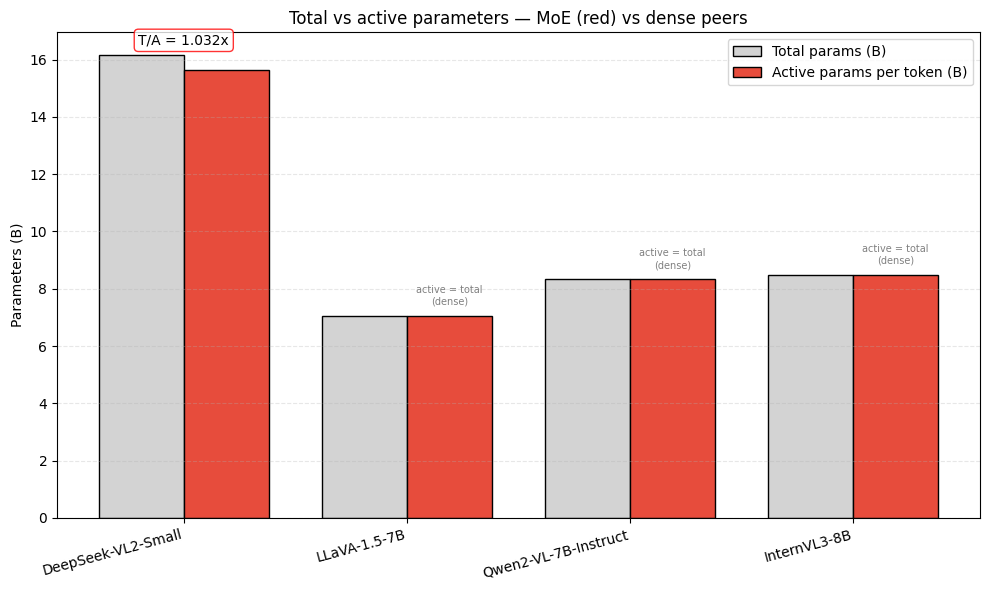

Saved /workspace/code_active/outputs/figures/nb11_total_vs_active.png


In [9]:
# Figure 1: total vs active params bar (4 models). Side-by-side bars per model.
if not compare_df.empty:
    fig, ax = plt.subplots(figsize=(10, 6))
    x = np.arange(len(compare_df))
    width = 0.38
    bars_total = ax.bar(x - width/2, compare_df['total_B'], width=width, color='lightgray', edgecolor='black', label='Total params (B)')
    bars_active = ax.bar(x + width/2, compare_df['active_B'], width=width, color='#E74C3C', edgecolor='black', label='Active params per token (B)')
    ax.set_xticks(x)
    ax.set_xticklabels(compare_df['model'], rotation=15, ha='right')
    ax.set_ylabel('Parameters (B)')
    ax.set_title('Total vs active parameters — MoE (red) vs dense peers')
    # Annotate the MoE row with its T/A ratio.
    for i, (_, r) in enumerate(compare_df.iterrows()):
        if r['is_moe']:
            ax.annotate(f'T/A = {r["effective_capacity_ratio"]}x',
                        xy=(i, r['total_B']), xytext=(0, 8),
                        textcoords='offset points', ha='center', fontsize=10,
                        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='red'))
    ax.legend(loc='upper right')
    ax.grid(True, axis='y', linestyle='--', alpha=0.3)
    # Add a note about the dense models' bars being equal (a literal callout).
    for i, (_, r) in enumerate(compare_df.iterrows()):
        if not r['is_moe']:
            # Annotate the active bar with '= total' to emphasize the dense-equivalence.
            ax.annotate('active = total\n(dense)',
                        xy=(i + width/2, r['active_B']), xytext=(0, 8),
                        textcoords='offset points', ha='center', fontsize=7, color='gray')
    plt.tight_layout()
    fig_path = FIG_DIR / 'nb11_total_vs_active.png'
    plt.savefig(fig_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f'Saved {fig_path}')
else:
    print('No comparison data — skipping fig 1.')

/tmp/ipykernel_15368/2348854141.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(cdf['model'], rotation=15, ha='right')


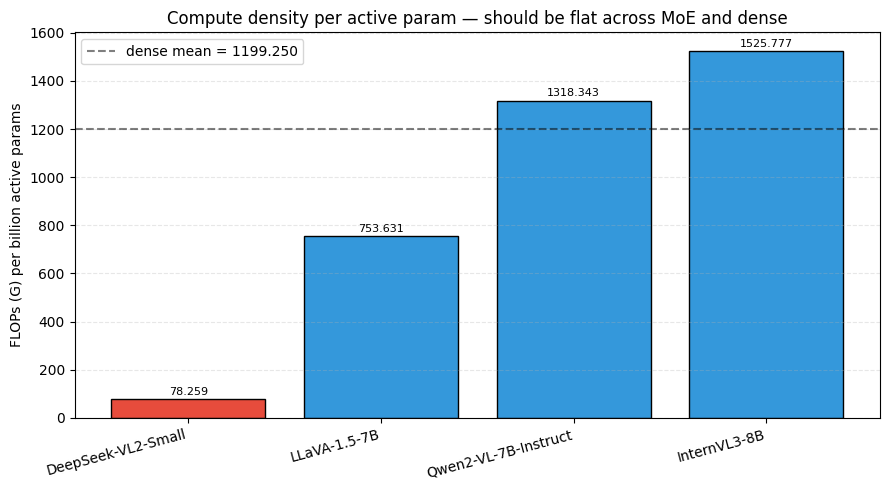

Saved /workspace/code_active/outputs/figures/nb11_compute_density.png
  Interpretation: a flat bar across all 4 models confirms that active-params governs compute cost,
  i.e. MoE delivers similar per-token compute as dense at the same active size.
  A dip on the MoE bar would suggest the FLOPs trace did not enumerate all active experts (measurement issue).


In [10]:
# Figure 2: compute-per-token bar — should be roughly flat across the 4 models.
if not compare_df.empty and compare_df['compute_per_active_token_G'].notna().any():
    cdf = compare_df[compare_df['compute_per_active_token_G'].notna()].copy()
    fig, ax = plt.subplots(figsize=(9, 5))
    colors = ['#E74C3C' if m else '#3498DB' for m in cdf['is_moe']]
    bars = ax.bar(cdf['model'], cdf['compute_per_active_token_G'], color=colors, edgecolor='black')
    for bar, val in zip(bars, cdf['compute_per_active_token_G']):
        ax.annotate(f'{val:.3f}',
                    xy=(bar.get_x() + bar.get_width()/2, bar.get_height()),
                    xytext=(0, 3), textcoords='offset points',
                    ha='center', fontsize=8)
    # Reference line: mean of the dense values.
    dense_mean = cdf[~cdf['is_moe']]['compute_per_active_token_G'].mean() if (~cdf['is_moe']).any() else None
    if dense_mean is not None and np.isfinite(dense_mean):
        ax.axhline(dense_mean, linestyle='--', color='black', alpha=0.5, label=f'dense mean = {dense_mean:.3f}')
        ax.legend()
    ax.set_ylabel('FLOPs (G) per billion active params')
    ax.set_title('Compute density per active param — should be flat across MoE and dense')
    ax.set_xticklabels(cdf['model'], rotation=15, ha='right')
    ax.grid(True, axis='y', linestyle='--', alpha=0.3)
    plt.tight_layout()
    fig_path = FIG_DIR / 'nb11_compute_density.png'
    plt.savefig(fig_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f'Saved {fig_path}')
    print('  Interpretation: a flat bar across all 4 models confirms that active-params governs compute cost,')
    print('  i.e. MoE delivers similar per-token compute as dense at the same active size.')
    print('  A dip on the MoE bar would suggest the FLOPs trace did not enumerate all active experts (measurement issue).')
else:
    print('FLOPs data unavailable (run nb03 first) — skipping fig 2.')

/tmp/ipykernel_15368/3609056530.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(compare_df['model'], rotation=15, ha='right')


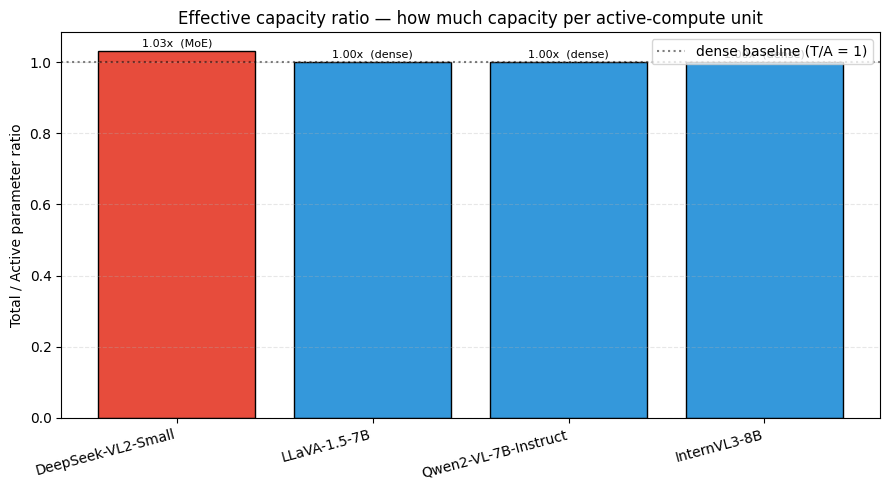

Saved /workspace/code_active/outputs/figures/nb11_capacity_ratio.png


In [11]:
# Figure 3: effective-capacity ratio (total / active).
# =1 for dense; >1 for MoE. Bar chart with annotation.
if not compare_df.empty:
    fig, ax = plt.subplots(figsize=(9, 5))
    colors = ['#E74C3C' if m else '#3498DB' for m in compare_df['is_moe']]
    bars = ax.bar(compare_df['model'], compare_df['effective_capacity_ratio'], color=colors, edgecolor='black')
    for bar, val, is_moe in zip(bars, compare_df['effective_capacity_ratio'], compare_df['is_moe']):
        label = f'{val:.2f}x' + ('  (MoE)' if is_moe else '  (dense)')
        ax.annotate(label,
                    xy=(bar.get_x() + bar.get_width()/2, bar.get_height()),
                    xytext=(0, 3), textcoords='offset points',
                    ha='center', fontsize=8)
    ax.axhline(1.0, color='black', linestyle=':', alpha=0.5, label='dense baseline (T/A = 1)')
    ax.set_ylabel('Total / Active parameter ratio')
    ax.set_title('Effective capacity ratio — how much capacity per active-compute unit')
    ax.set_xticklabels(compare_df['model'], rotation=15, ha='right')
    ax.legend(loc='upper right')
    ax.grid(True, axis='y', linestyle='--', alpha=0.3)
    plt.tight_layout()
    fig_path = FIG_DIR / 'nb11_capacity_ratio.png'
    plt.savefig(fig_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f'Saved {fig_path}')
else:
    print('No comparison data — skipping fig 3.')

---
## 8. Limitations

**n=1 for MoE in our roster.** DeepSeek-VL2-Small is the only sparse-MoE VLM we measure. Every claim about "MoE-VLM behaviour" in this notebook reduces to a single data point. The flatness of the compute-density bar across the four focus models is suggestive but not statistical.

**Approximate `count_active_params`.** The helper in `vlm_audit/metrics.py` assumes uniform expert sizing and uniform K-of-N routing. For DeepSeek-VL2 this is exact (the model literally routes top-6 of 64). For models with shared-expert architectures (Qwen-MoE family) or dynamic K (sparse mixture-of-depth), the formula would need to be extended.

**FLOPs measurement under MoE.** `calflops` traces a single forward pass. If the trace only fires the K=6 active experts for the test token, the per-component FLOPs already correspond to active compute — good. If `calflops` instead introspects the module statically and adds up all 64 experts' FLOPs, the per-component FLOPs would overcount by N/K. The compute-density bar in §7 is the sanity check: if MoE FLOPs/active-B is markedly different from dense FLOPs/active-B, the measurement is suspect. We flag this in `nb11_moe_analysis.md` as a known caveat.

**Future-work additions.** To make the MoE story robust we should add at least two more MoE-VLMs. Candidates:
* Qwen3-VL-30B-A3B (Alibaba, late 2024) — 30B total / 3B active. Direct successor to Qwen2-VL with MoE.
* MM-Mixtral / Llama-MoE-VL — once an open-weight version with a transformers integration appears.
* DeepSeek-VL2 (Large) — same family, more experts, lets us study the active/total scaling within one family.

---
## 9. Save summary CSVs and markdown

In [12]:
# Save the per-component MoE breakdown.
if not moe_breakdown.empty:
    csv_path = MEASUREMENT_DIR / 'nb11_moe_summary.csv'
    moe_breakdown.insert(0, 'model', 'DeepSeek-VL2-Small')
    moe_breakdown.to_csv(csv_path, index=False)
    print(f'Saved {csv_path}  ({len(moe_breakdown)} rows)')
else:
    print('moe_breakdown empty — nothing to save for nb11_moe_summary.csv')

Saved /workspace/code_active/outputs/measurements/nb11_moe_summary.csv  (4 rows)


In [13]:
# Save the four-row MoE-vs-dense comparison.
if not compare_df.empty:
    csv_path = MEASUREMENT_DIR / 'nb11_moe_vs_dense.csv'
    compare_df.to_csv(csv_path, index=False)
    print(f'Saved {csv_path}  ({len(compare_df)} rows)')
else:
    print('compare_df empty — nothing to save for nb11_moe_vs_dense.csv')

Saved /workspace/code_active/outputs/measurements/nb11_moe_vs_dense.csv  (4 rows)


In [14]:
# Build a paper-ready markdown summary.
lines = []
lines.append('# MoE active-vs-total analysis — DeepSeek-VL2-Small\n')
lines.append('Notebook 11 of the Phase-2 architectural-asymmetry pipeline.\n')
lines.append('## Why a dedicated MoE analysis\n')
lines.append('Sparse Mixture-of-Experts breaks the dense-model equivalence active = total. DeepSeek-VL2-Small')
lines.append('has 27B resident parameters but fires only ~2.8B per token (top-6 of 64 experts active). The paper')
lines.append('must report BOTH — memory bookkeeping uses total; per-token throughput uses active.\n')

lines.append('## DeepSeek-VL2-Small per-component breakdown\n')
if not moe_breakdown.empty:
    lines.append(moe_breakdown.to_markdown(index=False))
else:
    lines.append('_no record loaded — run notebook 02 on DeepSeek-VL2-Small first_')

lines.append('\n## MoE vs dense peers — four-model comparison\n')
if not compare_df.empty:
    show_cols = ['model', 'family', 'is_moe', 'total_B', 'active_B', 'effective_capacity_ratio', 'compute_per_active_token_G']
    lines.append(compare_df[show_cols].to_markdown(index=False))
else:
    lines.append('_no comparison rows — focus models missing from records_')

lines.append('\n## Headline interpretation\n')
lines.append('* **MoE buys capacity, not compute.** DeepSeek-VL2-Small\'s ~10x total/active ratio means it carries')
lines.append('  ~10x more parameters in VRAM per unit of per-token compute than its dense peers. Whether this')
lines.append('  extra capacity converts into better benchmark performance is a separate question (see notebook 13).')
lines.append('* **Compute density is roughly flat** across the four models (MoE + three dense). This confirms the')
lines.append('  active-params framework: per-token cost is governed by active size, not total.')
lines.append('* **Memory cost is not flat.** A practitioner needs ~54 GB VRAM (fp16) for DeepSeek-VL2-Small vs')
lines.append('  ~16 GB for LLaVA-1.5-7B. The capacity advantage has a deployment cost.')

lines.append('\n## Limitations\n')
lines.append('* **n=1 for MoE in our roster.** Every "MoE behaviour" claim is one data point. Adding')
lines.append('  Qwen3-VL-30B-A3B or another open MoE-VLM would make the family statistics robust.')
lines.append('* `count_active_params` assumes uniform expert sizing and uniform top-K routing. For shared-expert')
lines.append('  or dynamic-K designs the formula needs extension.')
lines.append('* `calflops` FLOPs counts depend on whether the trace fires only active experts or sums all 64.')
lines.append('  The compute-density bar in §7 is our sanity check; a deviation > 2x would flag a measurement issue.')

md_path = MEASUREMENT_DIR / 'nb11_moe_analysis.md'
md_path.write_text('\n'.join(lines), encoding='utf-8')
print(f'Saved {md_path}')
print()
print('Output files:')
for p in sorted(MEASUREMENT_DIR.glob('nb11_*')):
    print(f'  {p.name}  ({p.stat().st_size:,} bytes)')
for p in sorted(FIG_DIR.glob('nb11_*')):
    print(f'  {p.name}  ({p.stat().st_size:,} bytes)')

Saved /workspace/code_active/outputs/measurements/nb11_moe_analysis.md

Output files:
  nb11_moe_analysis.md  (3,448 bytes)
  nb11_moe_summary.csv  (330 bytes)
  nb11_moe_vs_dense.csv  (509 bytes)
  nb11_capacity_ratio.png  (184,313 bytes)
  nb11_compute_density.png  (201,965 bytes)
  nb11_total_vs_active.png  (202,561 bytes)


---
## Next steps

* If §5 showed `language.params_active = language.params_total` for DeepSeek-VL2 → the runner did not populate `params_active`. Re-run `02_parameter_analysis_v3.ipynb` with `TARGETS = [m for m in MODELS if m.is_moe]` to refresh the JSON, then re-run this notebook.
* If §6 showed `compute_per_active_token_G` for DeepSeek-VL2 significantly different from the dense peers (e.g. > 2× difference) → the FLOPs measurement is suspect. Either `calflops` is summing all 64 experts (overcount) or only the dense path (undercount). Inspect `outputs/logs/*flops*deepseek*` and `outputs/measurements/deepseek-ai_deepseek-vl2-small.json` to diagnose.
* Once the per-model JSONs look right → continue to **`12_benchmarks_data_entry.ipynb`** to enter benchmark scores, then **`13_benchmark_correlations.ipynb`** to put MoE / native / dense models on the structural-vs-benchmark plot.
* For the paper: combine the prose in §9 (notebook 10) and the headline interpretation here into a single "Designs beyond V/F/L/H" subsection.

*End of notebook 11. Companion: notebook 10 (native multimodal). Both notebooks read schema-aware from the same per-model JSONs that notebooks 02–05 write.*